<a href="https://colab.research.google.com/github/Arya-006/Youtube-Recommendation-System/blob/main/SONAR_Rock_vs_Mine_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
file_name = "sonar_dataset_416_rows_augmented.csv"
data = pd.read_csv(file_name, header=None)

print(f"Dataset loaded successfully using file: {file_name}!")
print("Dataset shape:", data.shape)
display(data.head())

Dataset loaded successfully using file: sonar_dataset_416_rows_augmented.csv!
Dataset shape: (416, 61)


,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [ ]:
X = data.iloc[:, 0:10]
Y = data.iloc[:, 60]

print("Number of input features:", X.shape[1])
print("Number of samples:", X.shape[0])
print("Target classes:", Y.unique())

Number of input features: 10
Number of samples: 416
Target classes: ['R' 'M']


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=42,
    stratify=Y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 332
Testing rows: 84


In [ ]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf")
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, Y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
KNN trained successfully!
SVM trained successfully!
Random Forest trained successfully!


In [ ]:
results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    accuracy = accuracy_score(Y_test, predictions) * 100

    results.append({
        "Algorithm": name,
        "Accuracy (%)": round(accuracy, 2)
    })

results_df = pd.DataFrame(results).sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print("ACCURACY COMPARISON")
display(results_df)

best_model_name = results_df.iloc[0]["Algorithm"]
best_accuracy = results_df.iloc[0]["Accuracy (%)"]
best_model = models[best_model_name]

print("Best algorithm:", best_model_name)
print("Highest test accuracy:", best_accuracy, "%")

ACCURACY COMPARISON


,Algorithm,Accuracy (%)
0,KNN,82.14
1,Random Forest,82.14
2,SVM,78.57
3,Logistic Regression,66.67


Best algorithm: KNN
Highest test accuracy: 82.14 %


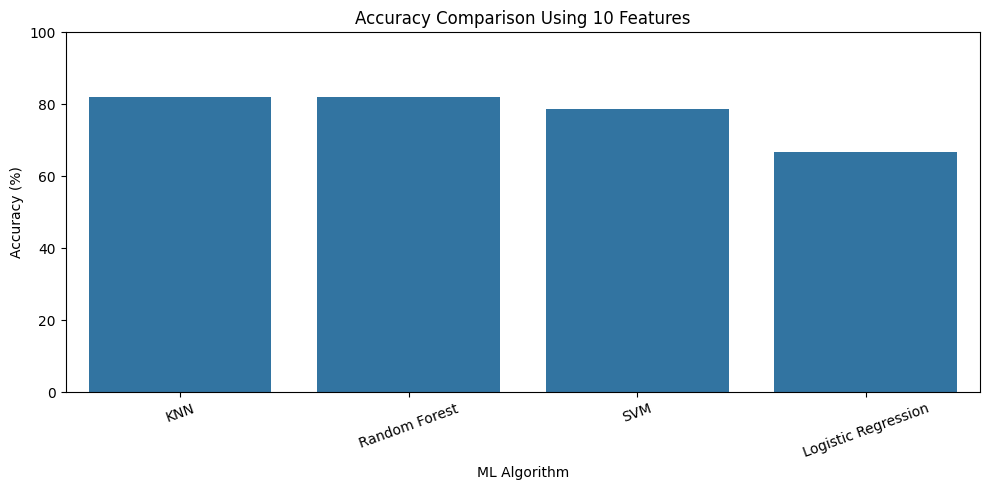

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="Accuracy (%)"
)

plt.title("Accuracy Comparison Using 10 Features")
plt.xlabel("ML Algorithm")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
for name, model in models.items():
    predictions = model.predict(X_test)

    print("\nAlgorithm:", name)

    print("\nConfusion Matrix:")
    print(confusion_matrix(
        Y_test, predictions, labels=["M", "R"]
    ))

    print("\nClassification Report:")
    print(classification_report(
        Y_test,
        predictions,
        labels=["M", "R"],
        target_names=["Mine", "Rock"],
        zero_division=0
    ))


Algorithm: Logistic Regression

Confusion Matrix:
[[30 15]
 [13 26]]

Classification Report:
              precision    recall  f1-score   support

        Mine       0.70      0.67      0.68        45
        Rock       0.63      0.67      0.65        39

    accuracy                           0.67        84
   macro avg       0.67      0.67      0.67        84
weighted avg       0.67      0.67      0.67        84


Algorithm: KNN

Confusion Matrix:
[[39  6]
 [ 9 30]]

Classification Report:
              precision    recall  f1-score   support

        Mine       0.81      0.87      0.84        45
        Rock       0.83      0.77      0.80        39

    accuracy                           0.82        84
   macro avg       0.82      0.82      0.82        84
weighted avg       0.82      0.82      0.82        84


Algorithm: SVM

Confusion Matrix:
[[39  6]
 [12 27]]

Classification Report:
              precision    recall  f1-score   support

        Mine       0.76      0.87      0.

In [ ]:
sample = X_test.iloc[[0]]

prediction = best_model.predict(sample)[0]
actual = Y_test.iloc[0]

print("Best model:", best_model_name)
print("Predicted class:", prediction)
print("Actual class:", actual)

if prediction == "R":
    print("Prediction: Rock")
else:
    print("Prediction: Mine")

print("Correct prediction:", prediction == actual)

print("\n===== ACCURACY OF ALL MODELS =====")

for name, model in models.items():
    predictions = model.predict(X_test)
    accuracy = accuracy_score(Y_test, predictions) * 100
    print(f"{name}: {accuracy:.2f}%")

print("\n===== BEST MODEL ACCURACY =====")
print(f"{best_model_name}: {best_accuracy:.2f}%")

Best model: KNN
Predicted class: R
Actual class: R
Prediction: Rock
Correct prediction: True

===== ACCURACY OF ALL MODELS =====
Logistic Regression: 66.67%
KNN: 82.14%
SVM: 78.57%
Random Forest: 82.14%

===== BEST MODEL ACCURACY =====
KNN: 82.14%
